In [1]:
from src.model import RigParameters, RigSolver, DistanceCalculator

RIG = {
    "reach_left":         45.0,
    "reach_right":        45.8,
    "arm_height_left":    83.1,
    "arm_height_right":   84.1,
    "brace_left":         63.0,
    "brace_right":        63.0,
    "joint_height":      126.0,
    "pole_length":        84.0,
}

In [2]:
# ── enter one (range_left, range_right) pair per can ───────────
can_ranges = [
    (108, 136),   # can 0
    (102.4, 123.5),   # can 1
  # (115.0, 100.0),   # can 2  ← uncomment to add a third can
]
# ───────────────────────────────────────────────────────────────

In [3]:
positions = []
for i, (rL, rR) in enumerate(can_ranges):
    params = RigParameters(
        aL=RIG["reach_left"],  aR=RIG["reach_right"],
        hL=RIG["arm_height_left"], hR=RIG["arm_height_right"],
        bL=RIG["brace_left"],  bR=RIG["brace_right"],
        hJ=RIG["joint_height"], Lp=RIG["pole_length"],
        rL=rL, rR=rR,
    )
    result = RigSolver(params).solve()
    positions.append((result['x'], result['y']))
    print(f"Can {i} : x={result['x']:.1f} cm,  y={result['y']:.1f} cm")
    for w in result['warnings']:
        print(f"  WARNING : {w}")

print()
calc = DistanceCalculator(*positions)
for label, dist in calc.all_distances().items():
    print(f"{label} : {dist:.1f} cm")

Can 0 : x=111.1 cm,  y=38.1 cm
Can 1 : x=82.8 cm,  y=101.9 cm

post -> can 0 : 117.5 cm
post -> can 1 : 131.3 cm
can 0 -> can 1 : 64.5 cm


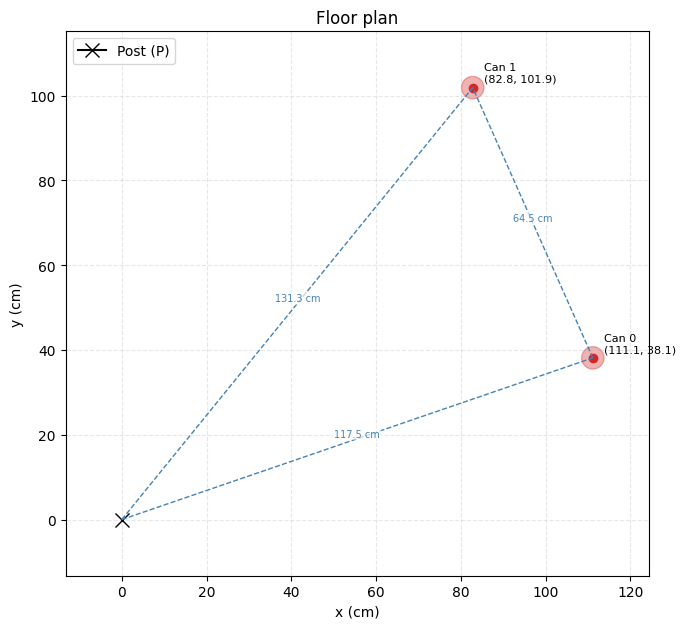

In [4]:
from src.visualise import FloorPlot

FloorPlot(positions).show()